 ### **4. Клиенты: повторные покупки через customer_unique_id, RFM, когорты**


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy.stats as st
from sqlalchemy import create_engine
import seaborn as sns

In [20]:
engine = create_engine("postgresql+psycopg2://a111@localhost:5432/olist")

ord = pd.read_sql("""select round(count(*) / count( distinct customer_unique_id) :: numeric, 2) as average_orders_count
from orders_delivered d join customers c
on d.customer_id = c.customer_id""", engine)
print(f'Среднее колво заказов на пользователя: {ord.average_orders_count.iat[0]}')

Среднее колво заказов на пользователя: 1.03


In [26]:
pd.read_sql("""
with base as (SELECT customer_unique_id, count(*) as orders
from orders_delivered d
join customers c
on d.customer_id = c.customer_id
group by customer_unique_id
order by orders desc),

base_1 as (select case when orders >= 3 then '3+' 
    else orders::text end as orders_per_customer,
    count(*) as customers
from base
group by orders_per_customer
order by orders_per_customer)

select orders_per_customer, round(customers / sum(customers) over() * 100, 2) as percentage
from base_1""", engine)

,orders_per_customer,percentage
0,1,97.00
1,2,2.75
2,3+,0.24


АНАЛИТИКА

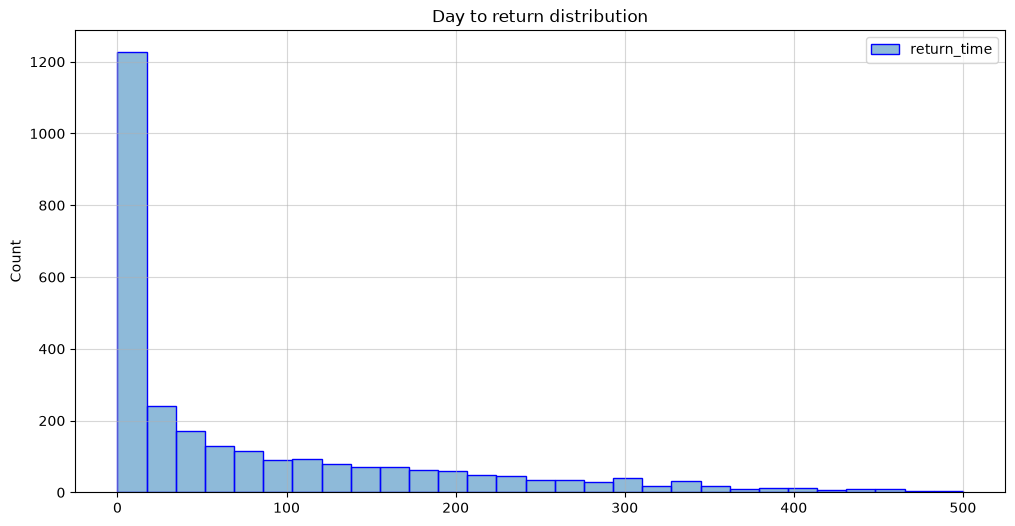

In [49]:
ret = pd.read_sql("""
with base as (
select customer_unique_id,
    order_purchase_timestamp,
    row_number() over (partition by customer_unique_id order by order_purchase_timestamp) as number_of_purchase
FROM orders_delivered d join customers c on c.customer_id = d.customer_id
where customer_unique_id in (
SELECT customer_unique_id
FROM orders_delivered d join customers c on c.customer_id = d.customer_id
group by customer_unique_id
having count(*) > 1)),

base_1 as (
select customer_unique_id,
MAX(CASE WHEN number_of_purchase = 1 THEN order_purchase_timestamp END) AS first_order_time, 
MAX(CASE WHEN number_of_purchase = 2 THEN order_purchase_timestamp END) AS second_order_time FROM base
GROUP BY customer_unique_id)

select second_order_time::date - first_order_time::date as return_time
from base_1""", engine)
plt.figure(figsize=(12,6))
plt.grid(alpha=0.5)
sns.histplot(data=ret, binrange=(0, 500), edgecolor='blue')
plt.title('Day to return distribution')
plt.savefig('../images/days_to_return_distr.png', dpi=150, bbox_inches='tight')
plt.show()

In [47]:
first = pd.read_sql("""
    WITH o AS (
        SELECT c.customer_unique_id,
               d.order_delivered_customer_date::date > d.order_estimated_delivery_date::date AS is_late,
               ROW_NUMBER() OVER (PARTITION BY c.customer_unique_id
                                  ORDER BY d.order_purchase_timestamp) AS rn,
               COUNT(*) OVER (PARTITION BY c.customer_unique_id) AS total_orders
        FROM orders_delivered d
        JOIN customers c ON c.customer_id = d.customer_id
    )
    SELECT CASE WHEN is_late THEN 'late' ELSE 'on time' END AS first_order,
           COUNT(*) AS customers,
           ROUND(100.0 * AVG((total_orders >= 2)::int), 2)::float AS repeat_pct
    FROM o
    WHERE rn = 1
    GROUP BY 1
""", engine)

first

,first_order,customers,repeat_pct
0,late,6356,2.58
1,on time,86740,3.03


При завозе вовремя шанс повторного заказа растет